In [19]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import log_loss, roc_auc_score
from import_folder import import_all_noiselevel_data, PQD_INDICES
from sklearn.feature_selection import mutual_info_classif
import matplotlib.pyplot as plt

# Now the same with all noise levels
from import_folder import import_all_noiselevel_data
folders = ['SNR_noiseless', 'SNR_50dB', 'SNR_40dB', 'SNR_30dB', 'SNR_20dB']

# 1. Load all noise levels into a single DataFrame
all_data = import_all_noiselevel_data(folders, add_noise_column=False)
X = all_data.drop(columns=['label'])
y = all_data['label']

In [20]:
# 1. Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

--- Feature Rankings ---
       Feature  ANOVA_F_Score  ANOVA_p_value  Mutual_Information
       min_TmA    4086.841818   0.000000e+00            1.100311
avg_abs_ST_3rd    3626.202807   0.000000e+00            1.062063
       max_TmA    1669.236039   0.000000e+00            1.043853
       std_TmA    1939.254844   0.000000e+00            0.974955
   std_FmA_3_7     486.627514   0.000000e+00            0.855544
   std_FmA_gt3    1391.010647   0.000000e+00            0.826146
 near_zero_cnt    2302.928597   0.000000e+00            0.747678
     num_peaks     122.783659  1.738234e-189            0.503215


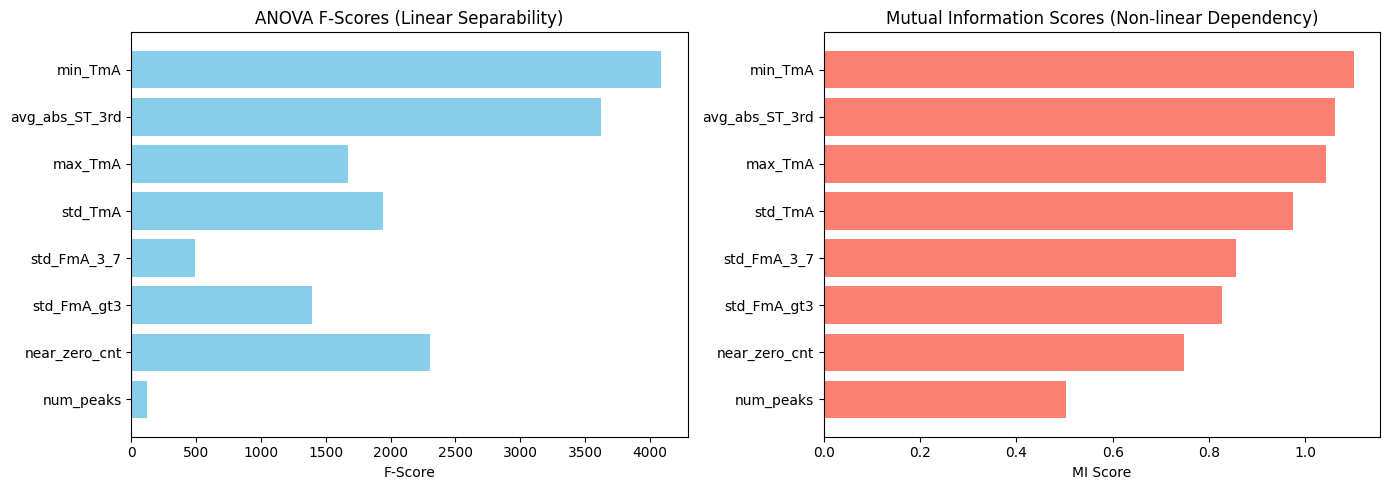

In [21]:
# 2. Compute ANOVA F-value (Linear/Parametric correlation with target class)
f_scores, f_pvalues = f_classif(X_train, y_train)

# 3. Compute Mutual Information (Non-linear/Information Theory based)
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

# 4. Combine into a summary DataFrame
ranking_df = pd.DataFrame(
    {
        "Feature": X_train.columns,
        "ANOVA_F_Score": f_scores,
        "ANOVA_p_value": f_pvalues,
        "Mutual_Information": mi_scores,
    }
).sort_values(by="Mutual_Information", ascending=False)

print("--- Feature Rankings ---")
print(ranking_df.to_string(index=False))

# 5. Plot Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot ANOVA F-scores
axes[0].barh(ranking_df["Feature"], ranking_df["ANOVA_F_Score"], color="skyblue")
axes[0].invert_yaxis()
axes[0].set_title("ANOVA F-Scores (Linear Separability)")
axes[0].set_xlabel("F-Score")

# Plot Mutual Information scores
axes[1].barh(
    ranking_df["Feature"], ranking_df["Mutual_Information"], color="salmon"
)
axes[1].invert_yaxis()
axes[1].set_title("Mutual Information Scores (Non-linear Dependency)")
axes[1].set_xlabel("MI Score")

plt.tight_layout()
plt.show()

In [22]:

# 2. Build Pipeline (Scaler -> Feature Selector -> Probabilistic Classifier)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('select_k', SelectKBest(score_func=f_classif, k=6)),  # Select top K features
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# 3. Fit Pipeline on Training Data
pipeline.fit(X_train, y_train)

# 4. Predict Class Probabilities on Unseen Test Data
# Result shape: (n_samples, 9) where each row sums to 1.0
y_probs = pipeline.predict_proba(X_test)

# 5. Evaluate Probabilistic Performance (e.g., Log-Loss or Multi-class ROC-AUC)
loss = log_loss(y_test, y_probs)
auc = roc_auc_score(y_test, y_probs, multi_class='ovr')

print(f"Log Loss: {loss:.4f}")
print(f"Multi-class ROC-AUC: {auc:.4f}")

Log Loss: 0.1814
Multi-class ROC-AUC: 0.9979


--- Feature Selection Performance by k ---
 k  mean_log_loss  std_log_loss  mean_roc_auc  std_roc_auc
 1       1.386808      0.005597      0.861456     0.001577
 2       0.761552      0.010176      0.958385     0.001927
 3       0.687022      0.012022      0.961127     0.001483
 4       0.380830      0.010030      0.983906     0.001374
 5       0.339214      0.010746      0.985846     0.000955
 6       0.190337      0.015910      0.997201     0.000870
 7       0.178459      0.014193      0.997486     0.000824
 8       0.163263      0.013281      0.997786     0.000608


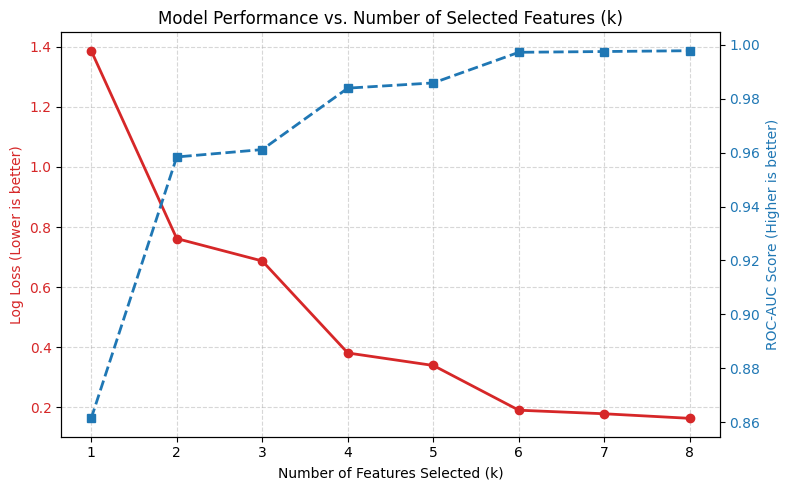

In [23]:
from sklearn.model_selection import StratifiedKFold

# 1. Setup Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

# 2. Loop over k from 1 to total number of features (8)
max_features = X.shape[1]

for k in range(1, max_features + 1):
    fold_losses = []
    fold_aucs = []

    for train_idx, val_idx in cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Pipeline with k features
        pipeline = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("select_k", SelectKBest(score_func=f_classif, k=k)),
                (
                    "classifier",
                    LogisticRegression(max_iter=1000, random_state=42),
                ),
            ]
        )

        pipeline.fit(X_train, y_train)
        y_probs = pipeline.predict_proba(X_val)

        # Calculate metrics for the fold
        fold_losses.append(log_loss(y_val, y_probs))
        fold_aucs.append(
            roc_auc_score(y_val, y_probs, multi_class="ovr", average="macro")
        )

    # Store mean metrics across 5 folds
    results.append(
        {
            "k": k,
            "mean_log_loss": np.mean(fold_losses),
            "std_log_loss": np.std(fold_losses),
            "mean_roc_auc": np.mean(fold_aucs),
            "std_roc_auc": np.std(fold_aucs),
        }
    )

# 3. Convert results to DataFrame
results_df = pd.DataFrame(results)

print("--- Feature Selection Performance by k ---")
print(results_df.to_string(index=False))

# 4. Plot Metrics vs Number of Features (k)
fig, ax1 = plt.subplots(figsize=(8, 5))

color = "tab:red"
ax1.set_xlabel("Number of Features Selected (k)")
ax1.set_ylabel("Log Loss (Lower is better)", color=color)
ax1.plot(
    results_df["k"],
    results_df["mean_log_loss"],
    marker="o",
    color=color,
    linewidth=2,
    label="Log Loss",
)
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
color = "tab:blue"
ax2.set_ylabel("ROC-AUC Score (Higher is better)", color=color)
ax2.plot(
    results_df["k"],
    results_df["mean_roc_auc"],
    marker="s",
    color=color,
    linewidth=2,
    linestyle="--",
    label="ROC-AUC",
)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Model Performance vs. Number of Selected Features (k)")
fig.tight_layout()
plt.show()

In [24]:
# Extract feature scores from SelectKBest
scores = pipeline.named_steps['select_k'].scores_

# Pair features with their scores and rank them
feature_rankings = pd.DataFrame({
    'Feature': X.columns,
    'F_Score': scores
}).sort_values(by='F_Score', ascending=False)

print("--- Features Ranked by Global Relevance ---")
print(feature_rankings.to_string(index=False))

--- Features Ranked by Global Relevance ---
       Feature     F_Score
       min_TmA 4023.265033
avg_abs_ST_3rd 3692.343674
 near_zero_cnt 2362.969068
       std_TmA 1888.578135
       max_TmA 1688.920467
   std_FmA_gt3 1372.524498
   std_FmA_3_7  493.092781
     num_peaks  118.145978


In [ ]:
import pandas as pd
from sklearn.feature_selection import f_classif

# Map class index back to class name
class_names = {v: k for k, v in PQD_INDICES.items()}

per_class_scores = {}

for class_idx in sorted(y.unique()):
    # Create binary target: 1 if current PQD class, 0 for all other classes
    y_binary = (y == class_idx).astype(int)
    
    # Compute ANOVA F-score for this specific class vs rest
    f_val, _ = f_classif(X, y_binary)
    per_class_scores[class_names[class_idx]] = f_val

# DataFrame showing top features for each specific PQD
class_importance_df = pd.DataFrame(per_class_scores, index=X.columns)

print("--- ANOVA F-Scores per Individual PQD Class ---")
print(class_importance_df.round(2))

--- ANOVA F-Scores per Individual PQD Class ---
                Normal     Sag    Swell  Interruption  Harmonics  \
avg_abs_ST_3rd  477.26  304.36   287.66        162.39    1633.72   
std_TmA         718.90  197.85   122.91       4040.88     718.15   
max_TmA          86.02  302.17  3057.21        539.87      85.34   
min_TmA         285.64  592.27   440.21       7204.61     286.22   
num_peaks       260.55   72.62   129.63          3.95     362.43   
std_FmA_3_7     341.64  285.11   252.48        202.65     381.13   
std_FmA_gt3     245.47  220.09   134.50        105.60      62.16   
near_zero_cnt   223.81   32.74   158.33      20331.88       0.10   

                Sag_harmonics  Swell_harmonics  Transient  Flicker  
avg_abs_ST_3rd         543.23          4031.15     448.71   469.89  
std_TmA                209.69            87.46     708.44   539.67  
max_TmA                296.26          2693.95      82.49    36.62  
min_TmA                606.59           446.70     284.13   246